# ACT Demo: Tensor Branch-and-Bound

Tensor BaB (`verify_bab_batched`) repeats four steps:

1. Take K sub-problems from the pool, starting with the unsplit problem.
2. Stack them into tensor lanes: input sub-boxes for ACAS Xu, ReLU splits for CIFAR-100.
3. Compute a dual bound for every lane.
4. Prune certified lanes; stop on a concrete counterexample; otherwise split and return children to the pool.

| Case | Network | Property | Ground truth |
|---|---|---|---|
| Certified | `ACASXU_run2a_2_4_batch_2000.onnx` | `prop_3` | unsat |
| Falsified | `ACASXU_run2a_1_2_batch_2000.onnx` | `prop_2` | sat |
| Certified | `CIFAR100_resnet_medium.onnx` | `prop_idx_2525_sidx_2978_eps_0.0039` | unsat |
| CLIMB off/on | `CIFAR100_resnet_medium.onnx` | `prop_idx_8420_sidx_4285_eps_0.0039` | unsat |

## Step 1: Setup

Initialize the device, float64 and a fixed seed; the Gurobi license warning is harmless (Gurobi is not used). Download missing data with `python -m act.front_end --download acasxu_2023` (also `cifar100_2024` for Step 5).

In [1]:
import contextlib, gc, io, logging, os, sys, time
from pathlib import Path
# Make the repository importable when the kernel starts in ipynb/
act_root = os.path.dirname(os.path.dirname(os.path.abspath('__file__')))
if act_root not in sys.path:
    sys.path.insert(0, act_root)
logging.getLogger('act.front_end.vnnlib_loader').setLevel(logging.ERROR)
logging.getLogger('act.pipeline.verification.act2torch').setLevel(logging.WARNING)
import pandas as pd
import torch
%matplotlib inline
from act.util.device_manager import initialize_device
from act.util.path_config import get_project_root
from act.util.stats import VerifyStatus
from act.front_end.vnnlib_loader.create_specs import create_specs_from_paths
from act.front_end.model_synthesis import merge_split_relus, synthesize_models_from_specs
from act.pipeline.verification.torch2act import TorchToACT
from act.back_end.transfer_functions import set_solver_mode, set_transfer_function_mode
from act.back_end.verifier import get_assert_layer
from act.back_end.bab.bab import verify_bab_batched
from act.back_end.bab.violation import check_violations_batched
from act.back_end.solver.solver_torchlp import TorchLPSolver
from dataclasses import replace
from act.config.config import BaBConfig, DualConfig, BackendConfig, build_vnncomp_bab_config, load_bab_preset
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
initialize_device(DEVICE, "float64")
torch.manual_seed(0)  # BaB pops sub-boxes in random order (bounding="random")
DATA = Path(get_project_root()) / "data" / "vnnlib"

[ACT] Auto-detecting project root: ..
[WARN] Gurobi license not found: ../modules/gurobi/gurobi.lic
[INFO] Please place gurobi.lic in: ../modules/gurobi
✅ Device Manager Initialized: device=cuda:0, dtype=torch.float64, tf32=off


## Step 2: ACT's verification flow

`build_net` follows the VNN-COMP runner: `create_specs_from_paths` -> `merge_split_relus` -> `synthesize_models_from_specs` -> `TorchToACT`. `trace_frame` converts cumulative trace time to seconds per iteration.

In [2]:
def build_net(onnx, vnnlib):
    """Build the ACT net (with INPUT_SPEC and ASSERT layers) of one instance under data/vnnlib; return (net, sr)."""
    # same steps as vnncomp/act_run_instance.py
    with contextlib.redirect_stdout(io.StringIO()):  # hide the loader banners
        sr = create_specs_from_paths(DATA / onnx, DATA / vnnlib)
        model, n_merged = merge_split_relus(sr[2])
        if n_merged:
            sr = tuple(model if i == 2 else v for i, v in enumerate(sr))
        (wrapped,) = synthesize_models_from_specs([sr]).values()
    return TorchToACT(wrapped).run(), sr

def trace_frame(trace) -> pd.DataFrame:
    """Return the five iteration counters, with incremental seconds."""
    df = pd.DataFrame(trace).set_index("iter")
    df["seconds"] = df["elapsed_s"].diff().fillna(df["elapsed_s"])
    return df.rename(columns={"pruned_unsat": "pruned", "pool_after": "pool"})[["K", "pruned", "branched", "pool", "seconds"]]

set_solver_mode("dual")
set_transfer_function_mode("interval")
ACAS_CFG = BaBConfig(solver_tier="dual", branching_method="width", max_depth=40, max_nodes=5_000_000)

## Step 3: Certified case (`prop_3`, net 2_4)

K grows as lanes split, then pruning drains the pool. CERTIFIED means every sub-box has been pruned; each row records one batched bounding pass.

In [3]:
cert_net, _ = build_net("acasxu_2023/onnx/ACASXU_run2a_2_4_batch_2000.onnx", "acasxu_2023/vnnlib/prop_3.vnnlib")
cert_trace, t0 = [], time.perf_counter()
cert = verify_bab_batched(cert_net, solver_factory=TorchLPSolver, config=ACAS_CFG, max_batch_size=1024,
                          time_budget_s=600.0, dual_config=DualConfig(), trace=cert_trace)
cert.metadata["seconds"] = round(time.perf_counter() - t0, 2)
assert cert.status == VerifyStatus.CERTIFIED, cert.status  # ground truth: unsat
assert cert.metadata["iterations"] > 1 and max(row["K"] for row in cert_trace) > 1, "expected batched branching"
display(trace_frame(cert_trace).round(3))

,K,pruned,branched,pool,seconds
iter,,,,,
1,1,0,1,2,0.475
2,2,0,2,4,0.052
3,4,0,4,8,0.048
4,8,0,8,16,0.046
5,16,3,13,26,0.033
6,26,3,23,46,0.033
7,46,7,39,78,0.035
8,78,10,68,136,0.039
9,136,31,105,210,0.068


## Step 4: Falsified case (`prop_2`, net 1_2)

BaB splits until a lane produces a concrete counterexample.

In [4]:
fals_net, fals_sr = build_net("acasxu_2023/onnx/ACASXU_run2a_1_2_batch_2000.onnx", "acasxu_2023/vnnlib/prop_2.vnnlib")
fals_trace, t0 = [], time.perf_counter()
fals = verify_bab_batched(fals_net, solver_factory=TorchLPSolver, config=ACAS_CFG, max_batch_size=1024,
                          time_budget_s=600.0, dual_config=DualConfig(), trace=fals_trace)
fals.metadata["seconds"] = round(time.perf_counter() - t0, 2)
assert fals.status == VerifyStatus.FALSIFIED, fals.status  # ground truth: sat
assert fals.metadata["iterations"] > 1 and max(row["K"] for row in fals_trace) > 1, "expected batched branching"

### The counterexample

Check the input box and `check_violations_batched`, then confirm COC has the maximal score, forbidden by `prop_2`. The bars compare the witness with the input bounds.

inside the input box: True; check_violations_batched: [True]
COC            -0.017482
weak left      -0.018223
weak right     -0.017879
strong left    -0.017597
strong right   -0.017978


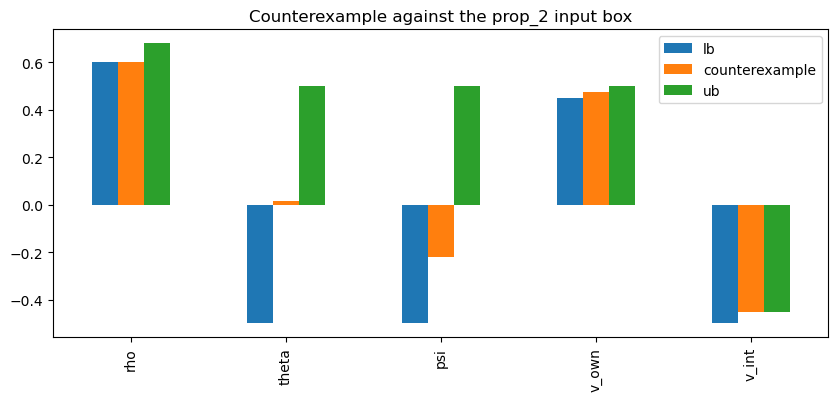

In [5]:
in_spec, _ = fals_sr[4][0]  # the (InputSpec, OutputSpec) pair parsed from the VNNLIB file
lb, ub, x = in_spec.lb.flatten().cpu(), in_spec.ub.flatten().cpu(), fals.counterexample.flatten()
inside = bool(((lb <= x) & (x <= ub)).all())
violated = check_violations_batched(fals_net, fals.counterexample[None].to(DEVICE), get_assert_layer(fals_net))
print(f"inside the input box: {inside}; check_violations_batched: {violated.tolist()}")
assert inside, "counterexample leaves the input box"
assert bool(violated.all()), "counterexample does not violate the property"
model = fals_sr[2]  # the ONNX model as PyTorch
with torch.no_grad():
    y = model(x.reshape(fals_sr[3][0].tensor.shape).to(next(model.parameters()))).flatten()
scores = pd.Series(y.tolist(), index=["COC", "weak left", "weak right", "strong left", "strong right"])
print(scores.to_string())
assert scores.idxmax() == "COC", "expected COC to have the maximal score"
box = pd.DataFrame({"lb": lb.numpy(), "counterexample": x.numpy(), "ub": ub.numpy()},
                   index=["rho", "theta", "psi", "v_own", "v_int"])
box.plot.bar(figsize=(10, 4), title="Counterexample against the prop_2 input box");

## Step 5: CIFAR-100 ResNet (neuron splitting)

Use the runner's `gain` profile, alpha-eta dual bounds, float32 and a 100 s budget. On CUDA, `max_batch_size="auto"` sizes K from available memory; `gain` splits four ReLU neurons into 16 children.

In [6]:
cifar, cifar_trace = None, []
if DEVICE == "cuda":
    initialize_device(DEVICE, "float32")
    set_solver_mode(None)  # the VNN-COMP runner leaves the solver mode unset
    set_transfer_function_mode("interval")
    cifar_net, _ = build_net("cifar100_2024/onnx/CIFAR100_resnet_medium.onnx",
                             "cifar100_2024/vnnlib/CIFAR100_resnet_medium_prop_idx_2525_sidx_2978_eps_0.0039.vnnlib")
    cfg, dual_cfg = build_vnncomp_bab_config("gain", solver_tier="dual_alpha_eta")
    cifar_trace, t0 = [], time.perf_counter()
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()  # auto K reads the process-wide peak
    cifar = verify_bab_batched(cifar_net, solver_factory=TorchLPSolver, config=cfg, max_batch_size="auto",
                               time_budget_s=100.0, dual_config=dual_cfg, trace=cifar_trace)
    cifar.metadata["seconds"] = round(time.perf_counter() - t0, 2)
    assert cifar.status == VerifyStatus.CERTIFIED, cifar.status  # ground truth: unsat
    assert cifar.metadata["iterations"] > 1 and max(row["K"] for row in cifar_trace) > 1, "expected batched branching"
else:
    print("skipped: the CIFAR-100 case needs a CUDA GPU")

✅ Device Manager Initialized: device=cuda:0, dtype=torch.float32, tf32=off


## Step 6: A frontier bottleneck

For CIFAR-100 idx_8420 (ground truth: unsat), BaB without CLIMB leaves unresolved sub-problems at the 100 s limit.

In [3]:
flip_off, flip_on = None, None
if DEVICE == "cuda":
    initialize_device(DEVICE, "float32")
    set_solver_mode("dual")
    backend = BackendConfig.from_yaml()
    flip_cfg = replace(backend.bab, **load_bab_preset("climb_split_lin"))
    flip_cfg = replace(flip_cfg, branching_method="fsb", presolve_time_fraction=0.3,
                       child_n_iters=10, max_nodes=10**12, max_depth=10**9, climb_enabled=False)
    flip_dual = replace(backend.dual, stagnation_patience=10, stop_when_verified=True)
    flip_paths = ("cifar100_2024/onnx/CIFAR100_resnet_medium.onnx",
                  "cifar100_2024/vnnlib/CIFAR100_resnet_medium_prop_idx_8420_sidx_4285_eps_0.0039.vnnlib")
    torch.manual_seed(0)
    flip_net, _ = build_net(*flip_paths)
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    flip_off_trace, t0 = [], time.perf_counter()
    flip_off = verify_bab_batched(flip_net, solver_factory=TorchLPSolver, config=flip_cfg,
        max_batch_size=256, time_budget_s=100.0, dual_config=flip_dual, trace=flip_off_trace)
    torch.cuda.synchronize()
    flip_off.metadata["seconds"] = round(time.perf_counter() - t0, 2)
    assert flip_off.status == VerifyStatus.UNKNOWN, flip_off.status
    assert flip_off.metadata["iterations"] > 1 and max(row["K"] for row in flip_off_trace) > 1
else:
    print("skipped: the CLIMB comparison needs a CUDA GPU")

✅ Device Manager Initialized: device=cuda:0, dtype=torch.float32, tf32=off


## Step 7: Enable CLIMB

Use the same model and budget; only `climb_enabled` changes. Derived cores count resolution results, not discharged nodes.

In [4]:
if DEVICE == "cuda":
    torch.manual_seed(0)
    flip_net, _ = build_net(*flip_paths)
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    flip_on_trace, t0 = [], time.perf_counter()
    flip_on = verify_bab_batched(flip_net, solver_factory=TorchLPSolver,
        config=replace(flip_cfg, climb_enabled=True), max_batch_size=256,
        time_budget_s=100.0, dual_config=flip_dual, trace=flip_on_trace)
    torch.cuda.synchronize()
    flip_on.metadata["seconds"] = round(time.perf_counter() - t0, 2)
    assert flip_on.status == VerifyStatus.CERTIFIED, flip_on.status
    assert flip_on.metadata["iterations"] > 1 and max(row["K"] for row in flip_on_trace) > 1
    display(pd.DataFrame([{
        "CLIMB": enabled, "verdict": result.status.name, "iterations": result.metadata["iterations"],
        "sub-problems": result.metadata["nodes"], "max K": max(row["K"] for row in trace),
        "seconds": result.metadata["seconds"], "derived cores": result.metadata.get("climb_cores_resolved", 0),
    } for enabled, result, trace in [("off", flip_off, flip_off_trace), ("on", flip_on, flip_on_trace)]
    ]).set_index("CLIMB"))

,verdict,iterations,sub-problems,max K,seconds,derived cores
CLIMB,,,,,,
off,UNKNOWN,39,7937,256,109.55,0
on,CERTIFIED,30,545,49,61.44,141


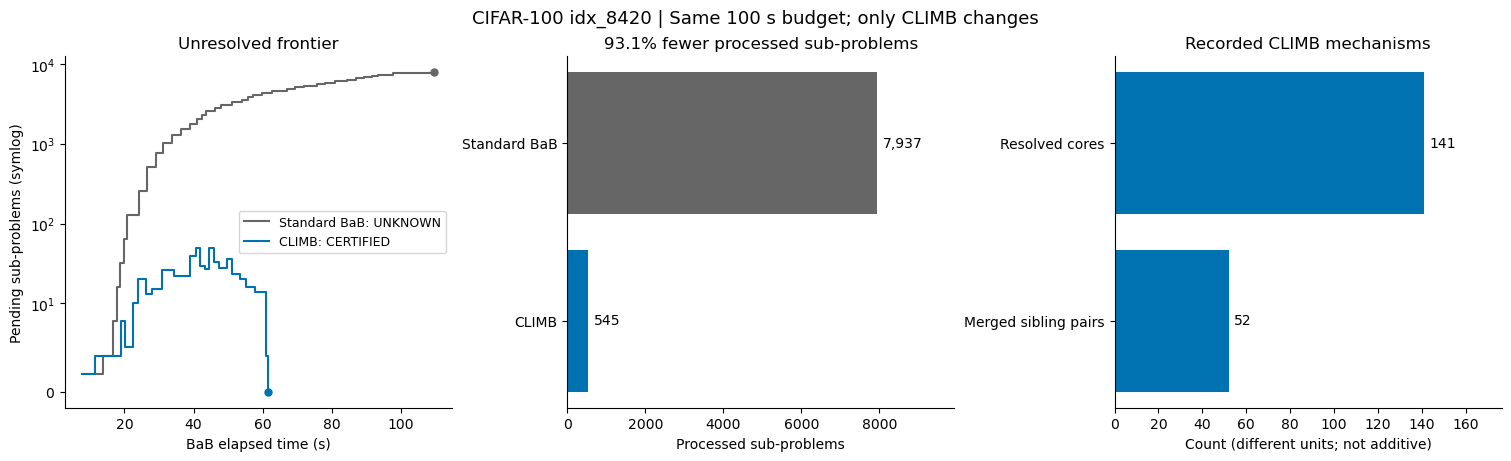

In [5]:
if DEVICE == "cuda":
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
    labels, colors = ["Standard BaB", "CLIMB"], ["#666666", "#0072B2"]
    for label, color, result, trace in zip(labels, colors, [flip_off, flip_on], [flip_off_trace, flip_on_trace]):
        frame = pd.DataFrame(trace)
        axes[0].step(frame["elapsed_s"], frame["pool_after"], where="post", color=color,
                        label=f"{label}: {result.status.name}")
        axes[0].scatter(frame["elapsed_s"].iloc[-1], frame["pool_after"].iloc[-1], color=color, s=25)
    axes[0].set(title="Unresolved frontier", xlabel="BaB elapsed time (s)", ylabel="Pending sub-problems (symlog)")
    axes[0].set_yscale("symlog", linthresh=10)
    axes[0].legend(fontsize=9)

    processed = [flip_off.metadata["nodes"], flip_on.metadata["nodes"]]
    reduction = 100 * (1 - processed[1] / processed[0])
    bars = axes[1].barh(labels, processed, color=colors)
    axes[1].bar_label(bars, labels=[f"{n:,}" for n in processed], padding=4)
    axes[1].set(title=f"{reduction:.1f}% fewer processed sub-problems", xlabel="Processed sub-problems",
                   xlim=(0, max(processed) * 1.25))
    axes[1].invert_yaxis()

    metrics = flip_on.metadata
    counts = [metrics["climb_cores_resolved"], metrics["climb_merged_pairs"]]
    bars = axes[2].barh(["Resolved cores", "Merged sibling pairs"], counts, color=colors[1])
    axes[2].bar_label(bars, labels=[f"{n:,}" for n in counts], padding=4)
    axes[2].set(title="Recorded CLIMB mechanisms", xlabel="Count (different units; not additive)",
                   xlim=(0, max(1, *counts) * 1.25))
    axes[2].invert_yaxis()
    fig.suptitle("CIFAR-100 idx_8420 | Same 100 s budget; only CLIMB changes", fontsize=13)
    for ax in axes.flat:
        ax.spines[["top", "right"]].set_visible(False)
    plt.show()

## Step 8: Summary

The three initial cases: verdict, ground truth, iterations, sub-problems, largest K and throughput.

In [8]:
runs = {name: (r, trace_frame(trace), branching, truth) for name, r, trace, branching, truth in [
    ("ACAS Xu prop_3 / 2_4", cert, cert_trace, "input", "unsat"),
    ("ACAS Xu prop_2 / 1_2", fals, fals_trace, "input", "sat"),
    ("CIFAR-100 idx_2525", cifar, cifar_trace, "neuron", "unsat")] if r is not None}
summary = pd.DataFrame([{"case": name, "branching": branching, "verdict": r.status.name, "ground truth": truth,
    "iterations": r.metadata["iterations"], "sub-problems": r.metadata["nodes"], "max K": int(df["K"].max()),
    "seconds": r.metadata["seconds"], "sub-problems/s": round(r.metadata["nodes"] / r.metadata["seconds"], 1)}
    for name, (r, df, branching, truth) in runs.items()]).set_index("case")
with pd.option_context("display.max_columns", None, "display.width", 200):
    display(summary)

,branching,verdict,ground truth,iterations,sub-problems,max K,seconds,sub-problems/s
case,,,,,,,,
ACAS Xu prop_3 / 2_4,input,CERTIFIED,unsat,13,619,210,1.14,543.0
ACAS Xu prop_2 / 1_2,input,FALSIFIED,sat,39,30603,1024,7.41,4130.0
CIFAR-100 idx_2525,neuron,CERTIFIED,unsat,3,17,8,23.54,0.7
